# 3. Crop health model: small, honest, and tested as shipped

**Goal:** a farmer photographs a bean leaf and gets a likely diagnosis, or an honest "not sure".

**Approach:** transfer learning. We reuse MobileNetV4, trained on ImageNet, as a fixed feature extractor and fit a small classifier on top. It trains on a laptop CPU in about a minute, which matters if your lab has no GPU.

In [1]:
import json, os, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["IMBUTO_ROOT"] = str(ROOT)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
GREEN, GREY, BROWN = "#1f6e3f", "#9aa89f", "#8c510a"

In [2]:
import io, time, warnings
warnings.filterwarnings("ignore")
import onnxruntime as ort
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from imbuto.ml.crop_health import preprocess, shrink_for_upload
from imbuto.ml import train as T
LABELS = T.LABELS
train_images, y_train = T._images("train"); val_images, y_val = T._images("validation")
print(len(train_images), "training images,", len(val_images), "validation images")

1034 training images, 133 validation images


## Features, then a classifier

We cut the network just before its 1,000-class ImageNet layer. Each photo becomes a list of 1,280 numbers.

In [3]:
start = time.perf_counter()
encoder = T._encoder_session(ROOT / "data/bronze/encoder/model.onnx")
x_train, x_val = T.embed(encoder, train_images), T.embed(encoder, val_images)
print(f"Embedded in {time.perf_counter() - start:.0f}s, shape {x_train.shape}")
scale = x_train.std()
for C in (0.01, 0.03, 0.1, 0.3, 1.0):
    model = LogisticRegression(C=C, max_iter=3000).fit(x_train / scale, y_train)
    print(f"C={C:<5} validation accuracy {accuracy_score(y_val, model.predict(x_val / scale)):.3f}")

Embedded in 10s, shape (1034, 1280)


C=0.01  validation accuracy 0.955
C=0.03  validation accuracy 0.932


C=0.1   validation accuracy 0.932
C=0.3   validation accuracy 0.932


C=1.0   validation accuracy 0.932


## The lesson: test the file you ship

Models are usually made smaller by **quantisation**. Dynamic quantisation is one line of code, and it runs with no errors or warnings about accuracy. Let us measure what it did.

In [4]:
from onnxruntime.quantization import quantize_dynamic, QuantType
head = LogisticRegression(C=0.01, max_iter=3000).fit(x_train / scale, y_train); head.coef_ = head.coef_ / scale
work = ROOT / "data"
T.export_onnx(ROOT / "data/bronze/encoder/model.onnx", head, work / "demo_float.onnx")
quantize_dynamic(work / "demo_float.onnx", work / "demo_dynamic.onnx", weight_type=QuantType.QUInt8)
def accuracy(path):
    session = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])
    predicted = [session.run(None, {"pixel_values": preprocess(Image.open(io.BytesIO(b)))[None]})[0].argmax() for b in val_images]
    return accuracy_score(y_val, predicted)
rows = [("float", "demo_float.onnx"), ("dynamic quantisation", "demo_dynamic.onnx"), ("static quantisation", "crop_health_quantised.onnx")]
results = pd.DataFrame([{"weights": n, "MB": round((work / f).stat().st_size / 1e6, 1), "validation accuracy": round(accuracy(work / f), 3)} for n, f in rows])
results

,weights,MB,validation accuracy
0,float,10.0,0.955
1,dynamic quantisation,2.6,0.338
2,static quantisation,2.8,0.902


The dynamic file is smaller, loads and answers with confidence, and is about as good as flipping a coin among three classes. **Nothing warned us.** Only measuring the exported file caught it.

Static quantisation is better but still loses accuracy here. Since this model runs on a server, where 10 MB costs nothing, we keep float weights. `imbuto.ml.train` now makes that choice automatically, and refuses to ship quantised weights that lose more than 2 points.

## Shipped model results

In [5]:
card = json.loads((ROOT / "artifacts/crop_health/bundle.json").read_text())["card"]
keep = ["test_images", "test_accuracy", "test_accuracy_after_2g_shrink", "answered_share", "accuracy_when_answered", "non_leaf_rejected", "real_leaf_wrongly_rejected", "median_upload_bytes", "model_bytes"]
pd.Series({k: card["metrics"][k] for k in keep}).to_frame("value")

,value
test_images,128.000
test_accuracy,0.922
test_accuracy_after_2g_shrink,0.875
answered_share,0.883
accuracy_when_answered,0.956
non_leaf_rejected,1.000
real_leaf_wrongly_rejected,0.031
median_upload_bytes,12335.000
model_bytes,9977656.000


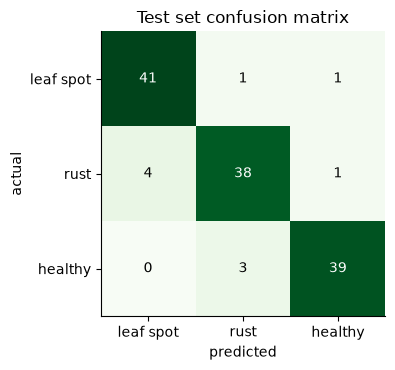

In [6]:
test_images, y_test = T._images("test")
session = ort.InferenceSession(str(ROOT / "artifacts/crop_health/model.onnx"), providers=["CPUExecutionProvider"])
probs = np.concatenate([session.run(None, {"pixel_values": preprocess(Image.open(io.BytesIO(b)))[None]})[0] for b in test_images])
matrix = confusion_matrix(y_test, probs.argmax(1))
fig, ax = plt.subplots(figsize=(4.4, 3.8)); ax.grid(False)
ax.imshow(matrix, cmap="Greens")
short = ["leaf spot", "rust", "healthy"]
ax.set(xticks=range(3), yticks=range(3), xticklabels=short, yticklabels=short, xlabel="predicted", ylabel="actual", title="Test set confusion matrix")
for (i, j), v in np.ndenumerate(matrix): ax.text(j, i, v, ha="center", va="center", color="white" if v > 20 else "black")
plt.tight_layout(); plt.show()

## The 2G cost of a photo

A camera photo can be 4 MB, which on 2G takes many minutes and often fails. So the browser shrinks it first. Sending less data has a price in accuracy, and it should be a chosen price. We picked 320 pixels at JPEG quality 40 on **validation** data, then measured once on test.

In [7]:
example = Image.open(io.BytesIO(test_images[0])); small = shrink_for_upload(example)
kbps = 40
print(f"Original test photo: {len(test_images[0]) / 1000:.0f} KB | after shrink: {len(small) / 1000:.1f} KB")
for name, size in {"4 MB camera photo": 4_000_000, "shrunk photo": len(small)}.items():
    print(f"{name:20} at {kbps} kbps: {size * 8 / (kbps * 1000):.1f} seconds")

Original test photo: 172 KB | after shrink: 16.6 KB
4 MB camera photo    at 40 kbps: 800.0 seconds
shrunk photo         at 40 kbps: 3.3 seconds


## Knowing when to say "I don't know"

Two checks sit in front of every answer:

- **Is this a leaf?** Cosine similarity to the average training photo.
- **Is the model sure?** Confidence must reach a threshold set on validation data.

The cost is that the model answers about 88% of the time. A wrong answer about a farmer's crop costs far more than a request for a better photo.

## What we may and may not claim

- Tested on 128 Ugandan images, so the true accuracy has a wide margin.
- The leaf check used small everyday images. **Leaves of other crops may pass it.**
- It covers one crop and two diseases, far short of the concept note's five crops.
- The note's 85% goal is for a *local* test set, which does not exist yet.

**Next:** notebook 4, where the model does not make it to farmers at all.